# APS2 — Classificação de Renda: Adult Income Census

**Disciplina:** Machine Learning — Insper, 2026.2
**Integrantes:** Gabriel Martins Rosa e João Pedro Baungartner
**Data de entrega:** 30/10/2026
**Etapa anterior:** APS1 — Análise Exploratória de Dados (mesmo dataset, mesmo split e mesmo pipeline)

---

## Objetivo

Prever se a renda anual de uma pessoa é superior a US$ 50 mil (`income = >50K`) a partir de
características demográficas e ocupacionais do censo americano de 1994, usando a versão do
[Adult Income Census disponibilizada no Kaggle](https://www.kaggle.com/datasets/anaghakp/adult-income-census)
(fonte primária: [UCI Machine Learning Repository](https://doi.org/10.24432/C5XW20)).

Esta etapa parte exatamente do ponto em que a APS1 terminou: os mesmos dados limpos, a mesma divisão
treino/teste e o mesmo pipeline de pré-processamento. Sobre essa base, comparamos três modelos,
ajustamos hiperparâmetros, testamos uma mudança no pipeline, avaliamos o melhor modelo no teste,
interpretamos as previsões e discutimos as limitações do resultado.

## Sumário

1. [Resumo executivo](#resumo-executivo)
2. [Preparação: dados e pipeline da APS1](#preparacao)
3. [Seção 1 — Seleção e implementação dos modelos](#secao-1)
4. [Seção 2 — Avaliação no conjunto de teste](#secao-2)
5. [Seção 3 — Interpretação e explicabilidade](#secao-3)
6. [Seção 4 — Discussão crítica](#secao-4)
7. [Conclusão](#conclusao)
8. [Referências](#referencias)

<a id="resumo-executivo"></a>
## Resumo executivo

| Etapa | Resultado principal |
|---|---|
| Métrica de seleção | **ROC-AUC**, com validação cruzada estratificada de 5 folds (os mesmos folds para todos os modelos) |
| Dummy (baseline) | AUC **0,500** — acurácia de 75,9% sem identificar nenhuma pessoa de renda alta |
| Logística regularizada (`GridSearchCV`) | AUC **0,884** (L2, C = 1); uma versão L1 com C = 0,1 empata (0,8835) usando só 33 das 89 colunas |
| Random Forest (`RandomizedSearchCV`) | AUC **0,890**; supera a logística nos 5 folds (+0,006 ± 0,001) |
| Mudança no pipeline | Remoção de `fnlwgt`: AUC **0,8904** (empate técnico), menor sobreajuste e modelo mais simples → **modelo final** |
| Curva de aprendizado | A validação estabiliza a partir de ~17 mil exemplos: o limite está nas features, não no volume de dados |
| Teste (usado uma única vez) | AUC **0,884**; com limiar 0,35 escolhido na validação: recall 75,6%, precisão 58,9%, F1 0,662 |
| Interpretação | Estado civil, escolaridade e idade são as variáveis mais relevantes (permutação e SHAP concordam) |
| Limitação mais grave | O modelo reconhece **60%** das mulheres de renda alta contra **78%** dos homens |

<a id="preparacao"></a>
## Preparação: dados e pipeline da APS1

Esta seção reproduz, sem alterações de conteúdo, as decisões da APS1:

- `?` e o valor inválido `occupation` foram convertidos em ausentes;
- as 65 linhas duplicadas foram removidas antes da separação treino/teste;
- divisão 80/20 estratificada com `random_state=42`;
- pipeline com mediana + padronização (`age`, `education_num`), mediana + `log1p` + padronização
  (`fnlwgt`), categoria explícita `Missing` + one-hot (categóricas) e descarte de `education`
  (redundante com `education_num`).

A única mudança de forma é a codificação do target em **0/1 (1 = renda >50K)**, que deixa explícita
a classe positiva para todas as métricas.

In [1]:
# Instala as bibliotecas que não vêm por padrão no Colab
%pip install -q kagglehub shap

Note: you may need to restart the kernel to use updated packages.


In [2]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, average_precision_score, brier_score_loss,
    confusion_matrix, f1_score, precision_recall_curve, precision_score, recall_score,
    roc_auc_score, roc_curve,
)
from sklearn.calibration import calibration_curve
from sklearn.model_selection import (
    GridSearchCV, RandomizedSearchCV, StratifiedKFold, cross_val_predict, cross_validate,
    learning_curve, train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

# Avisos de depreciação do scikit-learn não afetam os resultados; são silenciados para legibilidade
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
SEMENTE = 42

In [3]:
# Carregamento: usa o arquivo local se existir; caso contrário, baixa do Kaggle (igual à APS1)
arquivo_csv = Path("adult_income.csv")

if not arquivo_csv.exists():
    import kagglehub

    caminho_base = Path(kagglehub.dataset_download("anaghakp/adult-income-census"))
    arquivos_csv = list(caminho_base.rglob("*.csv"))
    if not arquivos_csv:
        raise FileNotFoundError("Nenhum arquivo CSV foi encontrado no dataset.")
    arquivo_csv = max(arquivos_csv, key=lambda p: p.stat().st_size)

df = pd.read_csv(arquivo_csv)
print("Arquivo utilizado:", arquivo_csv)
print("Dimensão original:", df.shape)

Arquivo utilizado: adult_income.csv
Dimensão original: (31947, 12)


In [4]:
# Limpeza idêntica à APS1
df.columns = df.columns.str.replace(".", "_", regex=False)

colunas_texto = [c for c in df.columns if pd.api.types.is_string_dtype(df[c])]
for coluna in colunas_texto:
    df[coluna] = df[coluna].str.strip()

df = df.replace("?", np.nan)                                       # '?' = ausência
df["occupation"] = df["occupation"].replace("occupation", np.nan)  # valor inválido

df_clean = df.drop_duplicates().reset_index(drop=True)
print("Dimensão após remover duplicatas:", df_clean.shape)

# Target em 0/1: 1 = renda anual > US$ 50 mil
X = df_clean.drop(columns="income")
y = (df_clean["income"] == ">50K").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEMENTE, stratify=y
)
print(f"Treino: {X_train.shape} | Teste: {X_test.shape}")
print(f"Proporção de renda >50K — treino: {y_train.mean():.4f} | teste: {y_test.mean():.4f}")

Dimensão após remover duplicatas: (31882, 12)
Treino: (25505, 11) | Teste: (6377, 11)
Proporção de renda >50K — treino: 0.2407 | teste: 0.2407


In [5]:
# Pipeline de pré-processamento da APS1, encapsulado numa função para permitir a
# variante sem fnlwgt (a mudança testada na Seção 1.6)
categoricas_modelo = [
    "workclass", "marital_status", "occupation", "relationship",
    "race", "sex", "native_country",
]

pipeline_numericas_regulares = Pipeline([
    ("imputacao", SimpleImputer(strategy="median")),
    ("padronizacao", StandardScaler()),
])

pipeline_fnlwgt = Pipeline([
    ("imputacao", SimpleImputer(strategy="median")),
    ("logaritmo", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("padronizacao", StandardScaler()),
])

pipeline_categoricas = Pipeline([
    ("imputacao", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("one_hot", OneHotEncoder(handle_unknown="ignore", sparse_output=True)),
])


def criar_preprocessador(com_fnlwgt=True):
    # com_fnlwgt=True reproduz exatamente o pipeline final da APS1 (89 colunas)
    transformadores = [
        ("numericas_regulares", pipeline_numericas_regulares, ["age", "education_num"]),
    ]
    if com_fnlwgt:
        transformadores.append(("fnlwgt", pipeline_fnlwgt, ["fnlwgt"]))
    transformadores.append(("categoricas", pipeline_categoricas, categoricas_modelo))
    return ColumnTransformer(transformadores, remainder="drop")


n_colunas = criar_preprocessador().fit_transform(X_train).shape[1]
print("Colunas geradas pelo pipeline da APS1:", n_colunas)

Colunas geradas pelo pipeline da APS1: 89


In [6]:
# Funções auxiliares usadas na interpretação

VARIAVEIS_ORIGINAIS = ["age", "education_num", "fnlwgt"] + categoricas_modelo


def nomes_colunas(modelo):
    # Nomes das colunas após o pré-processamento, sem o prefixo do transformador
    return [n.split("__", 1)[1] for n in modelo.named_steps["preprocessamento"].get_feature_names_out()]


def variavel_de_origem(coluna):
    # Mapeia uma coluna one-hot (ex.: 'occupation_Sales') para a variável original ('occupation')
    for variavel in VARIAVEIS_ORIGINAIS:
        if coluna == variavel or coluna.startswith(variavel + "_"):
            return variavel
    return coluna


def importancia_permutacao_cv(modelo, colunas, n_repeticoes=5):
    # Importância por permutação medida nos folds de validação (sem tocar no teste):
    # em cada fold, treina no restante e embaralha uma variável original por vez
    resultados = []
    for idx_treino, idx_valid in cv.split(X_train, y_train):
        m = clone(modelo).fit(X_train.iloc[idx_treino], y_train.iloc[idx_treino])
        r = permutation_importance(
            m, X_train.iloc[idx_valid][colunas], y_train.iloc[idx_valid],
            scoring="roc_auc", n_repeats=n_repeticoes, random_state=SEMENTE,
        )
        resultados.append(pd.Series(r.importances_mean, index=colunas))
    resultados = pd.concat(resultados, axis=1)
    return pd.DataFrame({"queda_AUC": resultados.mean(axis=1), "desvio": resultados.std(axis=1)})

<a id="secao-1"></a>
# Seção 1 — Seleção e implementação dos modelos

## 1.1 Métrica e estratégia de validação

**Métrica escolhida: ROC-AUC.** O AUC é a probabilidade de, sorteando uma pessoa de renda alta e
uma de renda baixa, o modelo atribuir nota maior à de renda alta. Três motivos para essa escolha:

1. **Desbalanceamento:** só 24,1% das pessoas têm renda >50K. A acurácia premia o classificador que
   ignora a classe minoritária (o dummy chega a 75,9%); o AUC dá 0,5 a qualquer modelo que não
   ordena as pessoas, e a comparação fica honesta.
2. **Independência do limiar:** o AUC avalia a capacidade de ordenar, não um corte específico. A
   escolha do limiar é uma decisão separada, feita na Seção 2 com precisão, recall e F1.
3. **Coerência com a avaliação final:** o ROC-AUC é exigido na Seção 2, e a mesma métrica guia a
   seleção do início ao fim.

O **PR-AUC** (*average precision*) é reportado como métrica complementar, por ser mais sensível ao
desempenho na classe minoritária.

**Validação:** um único objeto `StratifiedKFold(5, shuffle=True, random_state=42)` é usado em todas
as comparações, buscas de hiperparâmetros e curvas. Assim, todos os modelos fazem a mesma "prova", o
que permite comparar fold a fold. Todo o pré-processamento fica **dentro** do `Pipeline`, então é
reajustado em cada fold, sem vazamento. O conjunto de teste permanece intocado até a Seção 2.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)

METRICAS = {
    "ROC-AUC": "roc_auc",
    "PR-AUC": "average_precision",
    "Acurácia": "accuracy",
    "F1": "f1",
}


def como_texto(valor):
    # Converte parâmetros da busca em texto legível (None aparece como "None")
    return "None" if valor is None or (isinstance(valor, float) and np.isnan(valor)) else str(valor)


def resumo_cv(resultado):
    # Média ± desvio de cada métrica nos 5 folds de validação
    return {
        nome: f"{resultado[f'test_{nome}'].mean():.4f} ± {resultado[f'test_{nome}'].std():.4f}"
        for nome in METRICAS
    }

## 1.2 Modelo Dummy (baseline)

O `DummyClassifier(strategy="prior")` ignora todas as features e dá a mesma probabilidade (24,1%)
para todo mundo. Ele define o piso que qualquer modelo útil precisa superar.

In [8]:
modelo_dummy = Pipeline([
    ("preprocessamento", criar_preprocessador()),
    ("modelo", DummyClassifier(strategy="prior")),
])

resultado_dummy = cross_validate(modelo_dummy, X_train, y_train, cv=cv, scoring=METRICAS)
pd.DataFrame([resumo_cv(resultado_dummy)], index=["Dummy"])

,ROC-AUC,PR-AUC,Acurácia,F1
Dummy,0.5000 ± 0.0000,0.2407 ± 0.0001,0.7593 ± 0.0001,0.0000 ± 0.0000


O dummy tem **75,9% de acurácia sem aprender nada**: ele prevê `<=50K` para todos e nunca identifica
uma pessoa de renda alta (F1 = 0). Pelo ROC-AUC, recebe exatamente **0,500**, o valor do acaso. O
PR-AUC de 0,241 coincide com a proporção de positivos, que é o piso dessa métrica. Esse contraste
justifica a escolha do AUC: ele desmascara o baseline e a acurácia não.

## 1.3 Modelo linear com regularização: Regressão Logística

A regressão logística atribui um peso a cada coluna e converte a soma ponderada numa probabilidade.
A **regularização** penaliza pesos grandes, para evitar que o modelo dê importância exagerada a
padrões que aparecem por acaso no treino (por exemplo, em categorias com poucas pessoas).

Hiperparâmetros avaliados com `GridSearchCV` (24 combinações × 5 folds):

| Hiperparâmetro | Valores | Papel |
|---|---|---|
| `penalty` | L2, L1 | L2 encolhe todos os pesos; L1 pode zerar pesos, selecionando variáveis |
| `C` | 0,001 a 100 (escala log) | inverso da força da penalidade: **C pequeno = penalidade forte** |
| `class_weight` | `None`, `"balanced"` | aumenta o peso da classe minoritária no treino |

O solver `liblinear` foi escolhido por aceitar L1 e L2 e ser eficiente com matrizes esparsas
(resultado do one-hot).

In [9]:
pipeline_linear = Pipeline([
    ("preprocessamento", criar_preprocessador()),
    ("modelo", LogisticRegression(solver="liblinear", max_iter=5000)),
])

valores_C = [0.001, 0.01, 0.1, 1, 10, 100]
grade_linear = [
    {"modelo__penalty": ["l2"], "modelo__l1_ratio": [0], "modelo__C": valores_C,
     "modelo__class_weight": [None, "balanced"]},
    {"modelo__penalty": ["l1"], "modelo__l1_ratio": [1], "modelo__C": valores_C,
     "modelo__class_weight": [None, "balanced"]},
]

busca_linear = GridSearchCV(
    pipeline_linear, grade_linear, cv=cv, scoring="roc_auc",
    return_train_score=True, n_jobs=-1,
)
busca_linear.fit(X_train, y_train)

resultados_linear = pd.DataFrame(busca_linear.cv_results_)
resultados_linear = pd.DataFrame({
    "penalidade": resultados_linear["param_modelo__penalty"],
    "C": resultados_linear["param_modelo__C"].astype(float),
    "class_weight": resultados_linear["param_modelo__class_weight"].map(como_texto),
    "AUC_treino": resultados_linear["mean_train_score"],
    "AUC_validacao": resultados_linear["mean_test_score"],
    "desvio_validacao": resultados_linear["std_test_score"],
}).sort_values("AUC_validacao", ascending=False)

print("Melhor combinação:", busca_linear.best_params_)
print(f"AUC de validação: {busca_linear.best_score_:.4f}")
resultados_linear.head(8).round(4)

Melhor combinação: {'modelo__C': 1, 'modelo__class_weight': None, 'modelo__l1_ratio': 0, 'modelo__penalty': 'l2'}
AUC de validação: 0.8843


,penalidade,C,class_weight,AUC_treino,AUC_validacao,desvio_validacao
6,l2,1.0,None,0.8867,0.8843,0.0047
18,l1,1.0,None,0.8866,0.8842,0.0048
7,l2,1.0,balanced,0.8867,0.8841,0.0047
19,l1,1.0,balanced,0.8866,0.8840,0.0048
8,l2,10.0,None,0.8869,0.8840,0.0047
4,l2,0.1,None,0.8857,0.8840,0.0046
5,l2,0.1,balanced,0.8858,0.8840,0.0047
20,l1,10.0,None,0.8870,0.8839,0.0047


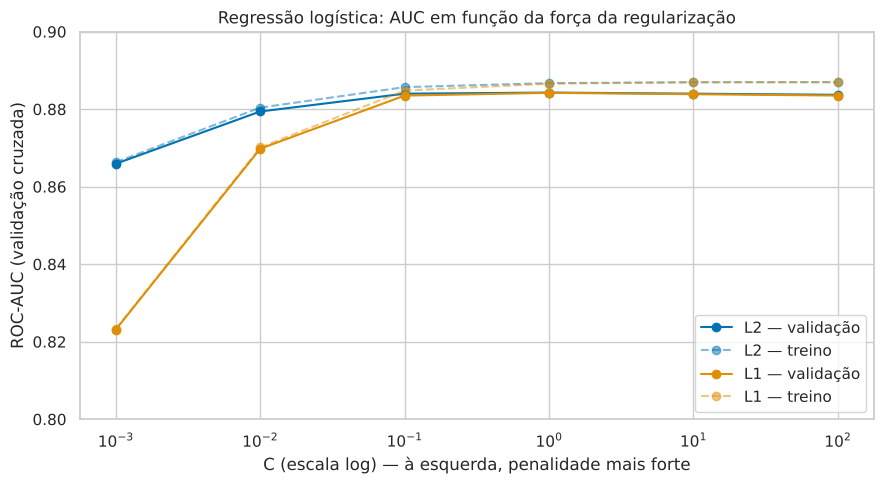

L1 com C=0.01: 78 de 89 coeficientes zerados


L1 com C=0.1: 56 de 89 coeficientes zerados


L1 com C=1: 27 de 89 coeficientes zerados


In [10]:
# Efeito da força da regularização (class_weight=None)
fig, ax = plt.subplots(figsize=(9, 5))
sem_peso = resultados_linear[resultados_linear["class_weight"] == "None"]

for penalidade, cor in [("l2", "C0"), ("l1", "C1")]:
    dados = sem_peso[sem_peso["penalidade"] == penalidade].sort_values("C")
    ax.plot(dados["C"], dados["AUC_validacao"], "o-", color=cor, label=f"{penalidade.upper()} — validação")
    ax.plot(dados["C"], dados["AUC_treino"], "o--", color=cor, alpha=0.5, label=f"{penalidade.upper()} — treino")

ax.set_xscale("log")
ax.set_ylim(0.80, 0.90)
ax.set_title("Regressão logística: AUC em função da força da regularização")
ax.set_xlabel("C (escala log) — à esquerda, penalidade mais forte")
ax.set_ylabel("ROC-AUC (validação cruzada)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

# Quantas colunas a penalidade L1 zera
for C in [0.01, 0.1, 1]:
    m = clone(pipeline_linear).set_params(modelo__penalty="l1", modelo__l1_ratio=1, modelo__C=C)
    m.fit(X_train, y_train)
    zerados = int((m.named_steps["modelo"].coef_ == 0).sum())
    print(f"L1 com C={C}: {zerados} de {m.named_steps['modelo'].coef_.size} coeficientes zerados")

**Análise.**

- **Melhor combinação: L2 com C = 1, AUC de validação 0,884 ± 0,005**, muito acima do dummy.
- **Penalidade forte demais causa subajuste:** com C = 0,001 o AUC cai para 0,866 (L2) e 0,823 (L1),
  porque os pesos ficam pequenos demais até para os padrões reais.
- **A partir de C = 0,1 há um platô:** as diferenças entre as melhores combinações (≈ 0,001) são
  menores que o desvio entre folds (≈ 0,005), ou seja, empate técnico.
- **A L1 com C = 0,1 empata (0,8835) zerando 56 das 89 colunas.** Pela regra de preferir o modelo mais
  simples em caso de empate, ela é a melhor candidata para interpretação (Seção 3.1).
- **`class_weight="balanced"` não altera o AUC:** reponderar as classes muda principalmente a escala
  das probabilidades, não a ordem entre as pessoas, que é o que o AUC mede.
- **Não há sobreajuste** (treino 0,887 contra validação 0,884). O limite do modelo é o **viés**: uma
  soma ponderada não representa relações não lineares como a observada na APS1 para a idade, em que a
  taxa de renda alta sobe até os 50–59 anos e depois cai. Isso motiva um modelo baseado em árvores.

## 1.4 Modelo ensemble de árvores: Random Forest

A Random Forest treina centenas de árvores de decisão, cada uma com uma amostra bootstrap das pessoas
e um sorteio de colunas em cada divisão, e faz a média das probabilidades. Árvores dividem as
variáveis em faixas e capturam não linearidades e interações automaticamente; a média de árvores
diversas reduz a variância de uma árvore isolada (Breiman, 2001).

| Hiperparâmetro | Valores | Papel |
|---|---|---|
| `n_estimators` | 200, 300 | número de árvores |
| `max_features` | √p, 20%, 40% | colunas sorteadas por divisão: menos colunas, árvores mais diversas |
| `min_samples_leaf` | 1, 3, 5, 10, 20 | mínimo de pessoas por folha: controla quanto cada árvore decora |
| `max_depth` | sem limite, 20 | profundidade máxima |
| `class_weight` | `None`, `"balanced_subsample"` | peso da classe minoritária |

O espaço tem 120 combinações (600 ajustes com 5 folds). Como cada floresta é cara de treinar, usamos
`RandomizedSearchCV` com **15 combinações sorteadas**, que cobre bem o espaço a uma fração do custo.

> ⏱️ Esta célula leva cerca de 15 minutos num ambiente com 2 núcleos (como o Colab gratuito).

In [11]:
pipeline_ensemble = Pipeline([
    ("preprocessamento", criar_preprocessador()),
    ("modelo", RandomForestClassifier(random_state=SEMENTE, n_jobs=1)),
])

distribuicao_rf = {
    "modelo__n_estimators": [200, 300],
    "modelo__max_features": ["sqrt", 0.2, 0.4],
    "modelo__min_samples_leaf": [1, 3, 5, 10, 20],
    "modelo__max_depth": [None, 20],
    "modelo__class_weight": [None, "balanced_subsample"],
}

busca_rf = RandomizedSearchCV(
    pipeline_ensemble, distribuicao_rf, n_iter=15, cv=cv, scoring="roc_auc",
    return_train_score=True, random_state=SEMENTE, n_jobs=-1,
)
busca_rf.fit(X_train, y_train)


def tabela_busca_rf(busca):
    r = pd.DataFrame(busca.cv_results_)
    return pd.DataFrame({
        "n_estimators": r["param_modelo__n_estimators"],
        "max_features": r["param_modelo__max_features"].map(como_texto),
        "min_samples_leaf": r["param_modelo__min_samples_leaf"].astype(int),
        "max_depth": r["param_modelo__max_depth"].map(como_texto),
        "class_weight": r["param_modelo__class_weight"].map(como_texto),
        "AUC_treino": r["mean_train_score"],
        "AUC_validacao": r["mean_test_score"],
        "desvio_validacao": r["std_test_score"],
    }).sort_values("AUC_validacao", ascending=False)


resultados_rf = tabela_busca_rf(busca_rf)
print("Melhor combinação:", busca_rf.best_params_)
print(f"AUC de validação: {busca_rf.best_score_:.4f}")
resultados_rf.round(4)

Melhor combinação: {'modelo__n_estimators': 200, 'modelo__min_samples_leaf': 5, 'modelo__max_features': 0.2, 'modelo__max_depth': 20, 'modelo__class_weight': None}
AUC de validação: 0.8901


,n_estimators,max_features,min_samples_leaf,max_depth,class_weight,AUC_treino,AUC_validacao,desvio_validacao
0,200,0.2,5,20,None,0.9276,0.8901,0.0045
9,300,0.2,10,20,balanced_subsample,0.9144,0.8898,0.0046
1,300,0.2,10,20,None,0.9136,0.8898,0.0047
11,200,sqrt,3,None,balanced_subsample,0.9305,0.8889,0.0045
6,300,0.2,3,None,balanced_subsample,0.9525,0.8888,0.0040
10,200,0.2,20,None,None,0.9037,0.8888,0.0048
2,200,sqrt,5,None,None,0.9131,0.8883,0.0049
14,300,0.4,20,None,balanced_subsample,0.9133,0.8883,0.0046
5,200,sqrt,5,None,balanced_subsample,0.9136,0.8883,0.0046
4,200,0.4,10,None,None,0.9293,0.8879,0.0042


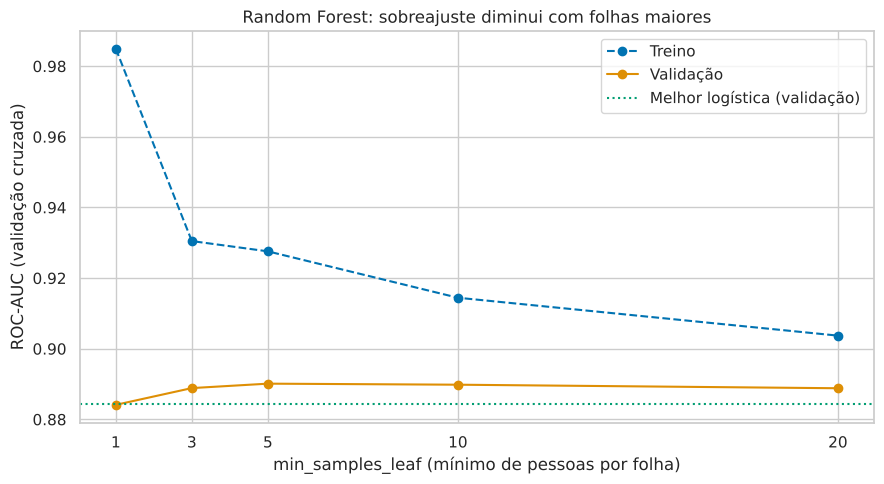

In [12]:
# Treino vs. validação em função do tamanho mínimo da folha (melhor configuração de cada valor)
melhor_por_folha = (
    resultados_rf.sort_values("AUC_validacao", ascending=False)
    .groupby("min_samples_leaf").head(1).sort_values("min_samples_leaf")
)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(melhor_por_folha["min_samples_leaf"], melhor_por_folha["AUC_treino"], "o--", label="Treino")
ax.plot(melhor_por_folha["min_samples_leaf"], melhor_por_folha["AUC_validacao"], "o-", label="Validação")
ax.axhline(busca_linear.best_score_, color="C2", linestyle=":", label="Melhor logística (validação)")
ax.set_xticks(melhor_por_folha["min_samples_leaf"])
ax.set_title("Random Forest: sobreajuste diminui com folhas maiores")
ax.set_xlabel("min_samples_leaf (mínimo de pessoas por folha)")
ax.set_ylabel("ROC-AUC (validação cruzada)")
ax.legend()
plt.tight_layout()
plt.show()

**Análise.**

- **Melhor combinação: 200 árvores, `min_samples_leaf=5`, `max_features=0.2`, `max_depth=20`, AUC de
  validação 0,890 ± 0,005.**
- **Folhas de 1 pessoa decoram o treino:** sem limite de profundidade, o AUC de treino chega a 1,000 e
  o de validação cai para 0,869, pior que a logística. Exigir ao menos 5 pessoas por folha impede que
  as árvores memorizem casos isolados e eleva a validação a 0,890.
- **`class_weight` novamente não altera o AUC**, pelo mesmo motivo discutido na logística.
- **Há sobreajuste moderado** (treino 0,928 contra validação 0,890), retomado na curva de aprendizado
  (Seção 1.7).

## 1.5 Comparação fold a fold

Como todos os modelos usaram os mesmos folds, a comparação é pareada: em cada fold, subtraímos o AUC
da logística do AUC da floresta. Isso elimina a variação causada pela dificuldade de cada fold.

In [13]:
def auc_por_fold(busca):
    # AUC de validação da melhor combinação em cada um dos 5 folds
    i = busca.best_index_
    return np.array([busca.cv_results_[f"split{k}_test_score"][i] for k in range(cv.get_n_splits())])


auc_dummy = resultado_dummy["test_ROC-AUC"]
auc_linear = auc_por_fold(busca_linear)
auc_rf = auc_por_fold(busca_rf)

comparacao = pd.DataFrame({
    "Dummy": auc_dummy,
    "Logística": auc_linear,
    "Random Forest": auc_rf,
    "Diferença (RF − Logística)": auc_rf - auc_linear,
}, index=[f"Fold {k + 1}" for k in range(5)])

display(comparacao.round(4))
dif = auc_rf - auc_linear
print(f"Diferença média: {dif.mean():+.4f} ± {dif.std():.4f} | folds em que a RF vence: {(dif > 0).sum()}/5")

,Dummy,Logística,Random Forest,Diferença (RF − Logística)
Fold 1,0.5,0.8905,0.8949,0.0044
Fold 2,0.5,0.8877,0.8935,0.0058
Fold 3,0.5,0.8785,0.8849,0.0064
Fold 4,0.5,0.8853,0.8928,0.0075
Fold 5,0.5,0.8794,0.8845,0.0051


Diferença média: +0.0058 ± 0.0011 | folds em que a RF vence: 5/5


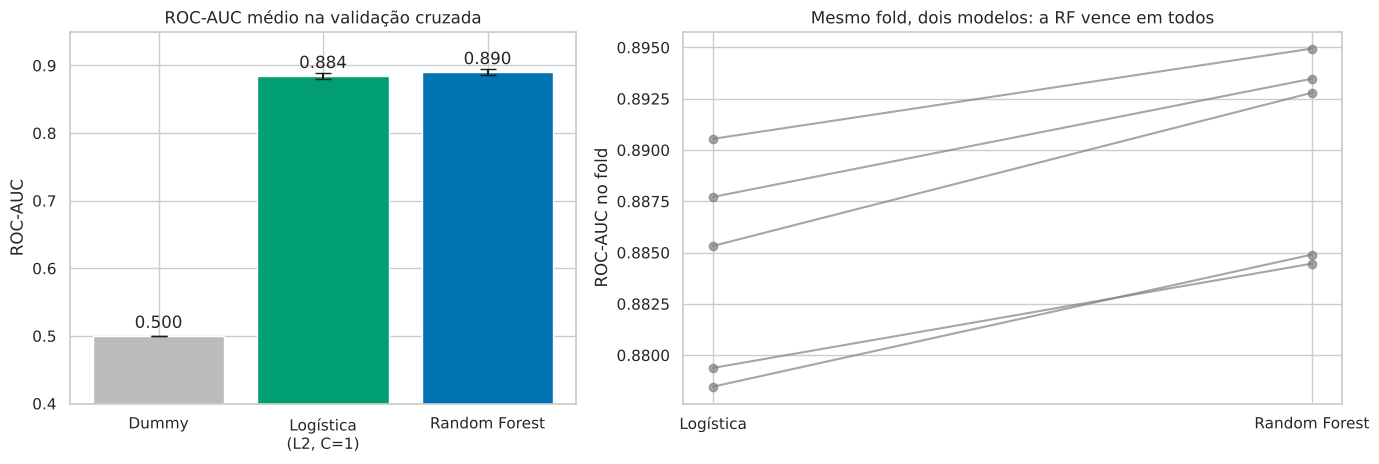

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1, 1.3]})

placar = pd.Series({"Dummy": auc_dummy.mean(), "Logística\n(L2, C=1)": auc_linear.mean(),
                    "Random Forest": auc_rf.mean()})
erros = [auc_dummy.std(), auc_linear.std(), auc_rf.std()]
axes[0].bar(placar.index, placar.values, yerr=erros, capsize=6, color=["#bbbbbb", "C2", "C0"])
for x, v in enumerate(placar.values):
    axes[0].text(x, v + 0.012, f"{v:.3f}", ha="center")
axes[0].set_ylim(0.4, 0.95)
axes[0].set_title("ROC-AUC médio na validação cruzada")
axes[0].set_ylabel("ROC-AUC")

for k in range(5):
    axes[1].plot(["Logística", "Random Forest"], [auc_linear[k], auc_rf[k]], "o-", color="gray", alpha=0.7)
axes[1].set_title("Mesmo fold, dois modelos: a RF vence em todos")
axes[1].set_ylabel("ROC-AUC no fold")
plt.tight_layout()
plt.show()

A floresta vence a logística **nos 5 folds**, com diferença média de **+0,006 ± 0,001**: a diferença é
cerca de cinco vezes maior que sua dispersão, portanto não se explica por variação entre folds. Os
folds difíceis (3 e 5) são difíceis para os dois modelos, o que reforça a importância da comparação
pareada. **A Random Forest é o melhor modelo até aqui** e é sobre ela que a mudança no pipeline é
avaliada.

## 1.6 Mudança no pipeline: remoção de `fnlwgt`

**Hipótese.** A APS1 deixou duas evidências contra o uso de `fnlwgt` como feature:

1. `fnlwgt` **não é um atributo da pessoa**: é o peso amostral do censo, que indica quantas pessoas da
   população cada registro representa. Em produção, ele nem existiria para um indivíduo novo.
2. Suas distribuições são praticamente iguais nas duas classes de renda (boxplots da APS1).

Esperamos que a importância por impureza (MDI) da floresta **superestime** `fnlwgt`: variáveis
contínuas com muitos valores distintos oferecem muitos pontos de corte para separar ruído no fundo das
árvores (Strobl et al., 2007). A importância por permutação, medida em dados não vistos, deve revelar
sua contribuição real. Se confirmada, a remoção deve simplificar o modelo sem perda de desempenho.

**Teste 1: MDI × permutação no modelo atual.** As importâncias das colunas one-hot são somadas por
variável original.

In [15]:
# MDI (treino) da melhor floresta, agregada por variável original
melhor_rf_com = busca_rf.best_estimator_
mdi = pd.Series(melhor_rf_com.named_steps["modelo"].feature_importances_, index=nomes_colunas(melhor_rf_com))
mdi_var = mdi.groupby(mdi.index.map(variavel_de_origem)).sum()

# Permutação (validação cruzada): embaralha uma variável original por vez
colunas_com_fnlwgt = ["age", "education_num", "fnlwgt"] + categoricas_modelo
perm_com = importancia_permutacao_cv(melhor_rf_com, colunas_com_fnlwgt)

importancias_com = pd.DataFrame({
    "MDI (treino)": mdi_var,
    "rank MDI": mdi_var.rank(ascending=False).astype(int),
    "Permutação: queda de AUC (validação)": perm_com["queda_AUC"],
    "rank permutação": perm_com["queda_AUC"].rank(ascending=False).astype(int),
}).sort_values("MDI (treino)", ascending=False)
importancias_com.round(4)

,MDI (treino),rank MDI,Permutação: queda de AUC (validação),rank permutação
education_num,0.2210,1,0.0526,2
marital_status,0.2159,2,0.0604,1
relationship,0.1876,3,0.0152,5
occupation,0.1198,4,0.0262,4
age,0.1121,5,0.0325,3
fnlwgt,0.0563,6,0.0007,9
workclass,0.0426,7,0.0063,6
sex,0.0284,8,0.0040,7
race,0.0083,9,0.0005,10
native_country,0.0081,10,0.0007,8


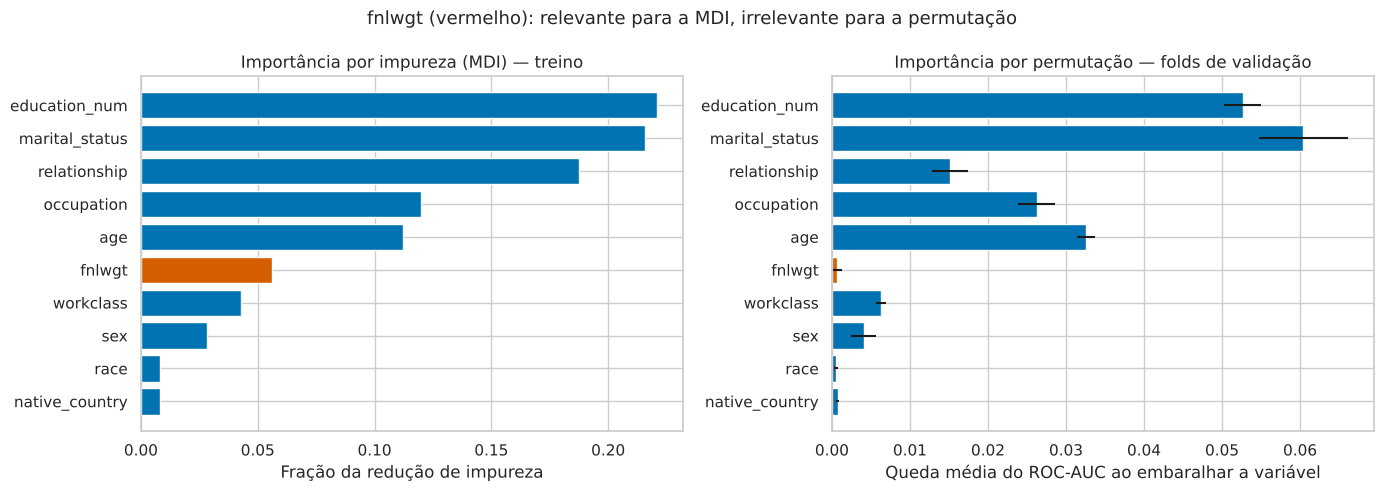

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ordem = importancias_com.index
cores = ["C3" if v == "fnlwgt" else "C0" for v in ordem]

axes[0].barh(ordem, importancias_com["MDI (treino)"], color=cores)
axes[0].invert_yaxis()
axes[0].set_title("Importância por impureza (MDI) — treino")
axes[0].set_xlabel("Fração da redução de impureza")

axes[1].barh(ordem, importancias_com["Permutação: queda de AUC (validação)"], color=cores,
             xerr=perm_com.loc[ordem, "desvio"])
axes[1].invert_yaxis()
axes[1].set_title("Importância por permutação — folds de validação")
axes[1].set_xlabel("Queda média do ROC-AUC ao embaralhar a variável")

plt.suptitle("fnlwgt (vermelho): relevante para a MDI, irrelevante para a permutação", fontsize=13)
plt.tight_layout()
plt.show()

A hipótese se confirma. Na MDI, `fnlwgt` aparece em **6º lugar (5,6%)**, à frente de `workclass` e
`sex`. Na permutação, embaralhá-lo reduz o AUC em apenas **0,0007**, empatado com as variáveis menos
úteis do modelo. A floresta usa `fnlwgt` para fazer cortes no treino, mas esses cortes não ajudam a
prever pessoas novas.

**Teste 2: nova seleção de hiperparâmetros sem `fnlwgt`.** Repetimos a mesma busca (mesma
distribuição, mesmas 15 combinações sorteadas, mesmos folds), mudando apenas o pipeline.

> ⏱️ Cerca de 13 minutos com 2 núcleos.

In [17]:
pipeline_ensemble_sem_fnlwgt = Pipeline([
    ("preprocessamento", criar_preprocessador(com_fnlwgt=False)),
    ("modelo", RandomForestClassifier(random_state=SEMENTE, n_jobs=1)),
])

busca_rf_sem = RandomizedSearchCV(
    pipeline_ensemble_sem_fnlwgt, distribuicao_rf, n_iter=15, cv=cv, scoring="roc_auc",
    return_train_score=True, random_state=SEMENTE, n_jobs=-1,
)
busca_rf_sem.fit(X_train, y_train)

resultados_rf_sem = tabela_busca_rf(busca_rf_sem)
print("Melhor combinação sem fnlwgt:", busca_rf_sem.best_params_)
print(f"AUC de validação: {busca_rf_sem.best_score_:.4f}")
resultados_rf_sem.head(6).round(4)

Melhor combinação sem fnlwgt: {'modelo__n_estimators': 200, 'modelo__min_samples_leaf': 5, 'modelo__max_features': 0.2, 'modelo__max_depth': 20, 'modelo__class_weight': None}
AUC de validação: 0.8904


,n_estimators,max_features,min_samples_leaf,max_depth,class_weight,AUC_treino,AUC_validacao,desvio_validacao
0,200,0.2,5,20,None,0.9181,0.8904,0.0051
1,300,0.2,10,20,None,0.9076,0.8902,0.0050
9,300,0.2,10,20,balanced_subsample,0.9083,0.8902,0.0050
4,200,0.4,10,None,None,0.9179,0.8893,0.0049
11,200,sqrt,3,None,balanced_subsample,0.9204,0.8891,0.0044
10,200,0.2,20,None,None,0.9000,0.8891,0.0051


In [18]:
auc_rf_sem = auc_por_fold(busca_rf_sem)
i_com, i_sem = busca_rf.best_index_, busca_rf_sem.best_index_

impacto = pd.DataFrame({
    "Com fnlwgt (APS1)": [
        busca_rf.cv_results_["mean_test_score"][i_com],
        busca_rf.cv_results_["mean_train_score"][i_com],
        busca_rf.cv_results_["mean_train_score"][i_com] - busca_rf.cv_results_["mean_test_score"][i_com],
        len(nomes_colunas(busca_rf.best_estimator_)),
    ],
    "Sem fnlwgt": [
        busca_rf_sem.cv_results_["mean_test_score"][i_sem],
        busca_rf_sem.cv_results_["mean_train_score"][i_sem],
        busca_rf_sem.cv_results_["mean_train_score"][i_sem] - busca_rf_sem.cv_results_["mean_test_score"][i_sem],
        len(nomes_colunas(busca_rf_sem.best_estimator_)),
    ],
}, index=["AUC validação", "AUC treino", "Distância treino − validação", "Número de colunas"])
display(impacto.round(4))

dif_mudanca = auc_rf_sem - auc_rf
print("AUC por fold (sem − com):", np.round(dif_mudanca, 4))
print(f"Diferença média: {dif_mudanca.mean():+.4f} ± {dif_mudanca.std():.4f} | folds com melhora: {(dif_mudanca > 0).sum()}/5")

,Com fnlwgt (APS1),Sem fnlwgt
AUC validação,0.8901,0.8904
AUC treino,0.9276,0.9181
Distância treino − validação,0.0375,0.0278
Número de colunas,89.0000,88.0000


AUC por fold (sem − com): [ 0.0012  0.0004  0.0001  0.0006 -0.001 ]
Diferença média: +0.0003 ± 0.0007 | folds com melhora: 4/5


**Análise do impacto.**

- **Desempenho: empate técnico.** A busca escolheu a mesma configuração de antes; o AUC passou de
  0,8901 para 0,8904. Fold a fold, a diferença é +0,0003 ± 0,0007, menor que a própria variação.
- **Menos sobreajuste:** a distância entre treino e validação caiu de 0,038 para 0,028, porque as
  árvores perderam uma variável contínua que servia principalmente para memorizar.
- **Modelo mais simples e defensável:** usa apenas atributos reais das pessoas, sem depender de um peso
  do desenho amostral que não existiria para um indivíduo novo.

**Decisão: o modelo final é a Random Forest sem `fnlwgt`.** Com desempenho estatisticamente
equivalente, preferimos o modelo mais simples, com menor sobreajuste e melhor justificativa conceitual.

## 1.7 Curva de aprendizado do melhor modelo

A curva de aprendizado fixa o modelo e varia o número de exemplos de treino (de 10% a 100% de cada
fold), medindo o AUC no treino e na validação. Ela indica se mais dados ajudariam. A logística aparece
como contraste.

,n_treino,RF treino,RF validação,Logística treino,Logística validação,RF distância
0,2040,0.9265,0.8805,0.8913,0.8789,0.0459
1,5101,0.9242,0.8861,0.8879,0.8827,0.0382
2,8161,0.9213,0.8878,0.8871,0.8836,0.0335
3,11222,0.9195,0.8890,0.8862,0.8834,0.0305
4,14282,0.9186,0.8899,0.8854,0.8837,0.0288
5,17343,0.9186,0.8904,0.8861,0.8839,0.0283
6,20404,0.9182,0.8904,0.8865,0.8841,0.0278


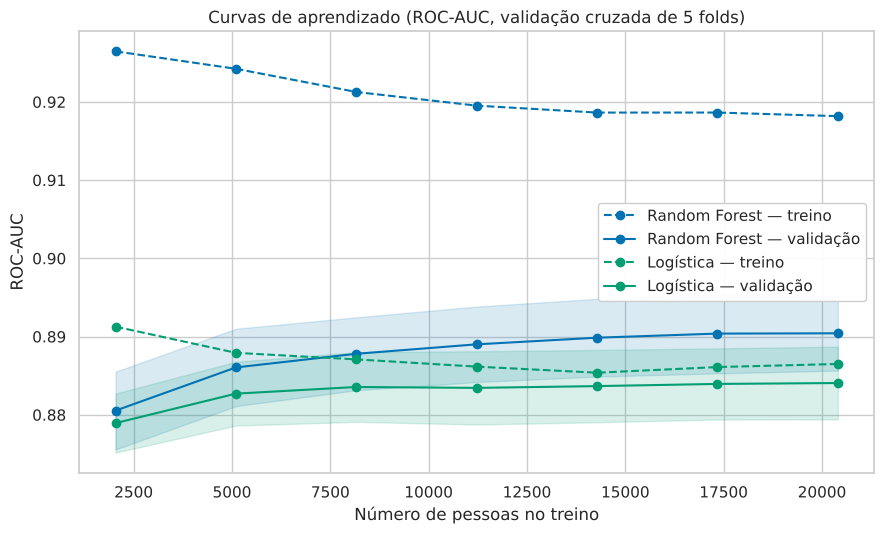

In [19]:
melhor_modelo = busca_rf_sem.best_estimator_
melhor_linear = clone(busca_linear.best_estimator_).set_params(
    preprocessamento=criar_preprocessador(com_fnlwgt=False)
)
tamanhos = np.linspace(0.1, 1.0, 7)

curvas = {}
for nome, modelo in [("Random Forest", melhor_modelo), ("Logística", melhor_linear)]:
    n, treino, validacao = learning_curve(
        clone(modelo), X_train, y_train, train_sizes=tamanhos, cv=cv,
        scoring="roc_auc", shuffle=True, random_state=SEMENTE, n_jobs=-1,
    )
    curvas[nome] = (n, treino, validacao)

tabela_curva = pd.DataFrame({
    "n_treino": curvas["Random Forest"][0],
    "RF treino": curvas["Random Forest"][1].mean(axis=1),
    "RF validação": curvas["Random Forest"][2].mean(axis=1),
    "Logística treino": curvas["Logística"][1].mean(axis=1),
    "Logística validação": curvas["Logística"][2].mean(axis=1),
})
tabela_curva["RF distância"] = tabela_curva["RF treino"] - tabela_curva["RF validação"]
display(tabela_curva.round(4))

fig, ax = plt.subplots(figsize=(9, 5.5))
for nome, cor in [("Random Forest", "C0"), ("Logística", "C2")]:
    n, treino, validacao = curvas[nome]
    ax.plot(n, treino.mean(axis=1), "o--", color=cor, label=f"{nome} — treino")
    ax.plot(n, validacao.mean(axis=1), "o-", color=cor, label=f"{nome} — validação")
    ax.fill_between(n, validacao.mean(axis=1) - validacao.std(axis=1),
                    validacao.mean(axis=1) + validacao.std(axis=1), color=cor, alpha=0.15)
ax.set_title("Curvas de aprendizado (ROC-AUC, validação cruzada de 5 folds)")
ax.set_xlabel("Número de pessoas no treino")
ax.set_ylabel("ROC-AUC")
ax.legend(loc="center right", framealpha=0.95)
plt.tight_layout()
plt.show()

**Análise.**

- **Random Forest:** com mais dados, a validação sobe (0,881 → 0,890) e o treino desce
  (0,927 → 0,918); as árvores decoram menos. A partir de ~17 mil exemplos a validação **estabiliza**, e
  resta uma distância de 0,028 que fecha cada vez mais devagar. Mais dados do mesmo tipo trariam ganho
  pequeno; avanços relevantes dependem de **features mais informativas** (ver Seção 4) ou de modelos
  mais expressivos.
- **Logística:** as curvas convergem rapidamente e ficam coladas em ≈ 0,884 (distância de 0,002). É o
  retrato de um modelo limitado por **viés**: mais dados não o melhorariam.

### Placar da Seção 1

| Modelo | ROC-AUC (validação cruzada) |
|---|---|
| Dummy | 0,500 |
| Regressão logística (L2, C = 1) | 0,884 ± 0,005 |
| Random Forest (pipeline da APS1) | 0,890 ± 0,005 |
| **Random Forest sem `fnlwgt` (modelo final)** | **0,890 ± 0,005** |

<a id="secao-2"></a>
# Seção 2 — Avaliação do melhor modelo no conjunto de teste

## 2.1 Escolha do limiar de decisão (sem olhar o teste)

O modelo produz uma probabilidade; o corte padrão de 0,5 não é obrigatório e costuma ser inadequado
com classes desbalanceadas. Escolher o corte olhando o teste o contaminaria. Por isso, usamos as
**previsões de validação cruzada no treino** (cada pessoa recebe a nota de um modelo que não a viu) e
escolhemos o limiar que maximiza o **F1**, equilibrando precisão e recall.

Limiar que maximiza o F1 na validação: 0.354 (F1 = 0.6757)
F1 na validação com limiar 0,5: 0.6299


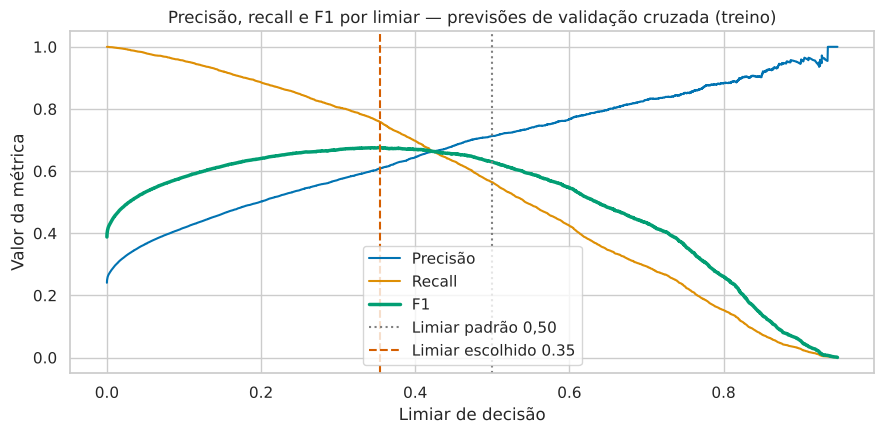

In [20]:
prob_validacao = cross_val_predict(clone(melhor_modelo), X_train, y_train, cv=cv,
                                   method="predict_proba", n_jobs=-1)[:, 1]

precisoes, recalls, limiares = precision_recall_curve(y_train, prob_validacao)
f1s = 2 * precisoes * recalls / (precisoes + recalls + 1e-12)
i_otimo = np.argmax(f1s[:-1])
LIMIAR = limiares[i_otimo]

print(f"Limiar que maximiza o F1 na validação: {LIMIAR:.3f} (F1 = {f1s[i_otimo]:.4f})")
print(f"F1 na validação com limiar 0,5: {f1_score(y_train, prob_validacao >= 0.5):.4f}")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(limiares, precisoes[:-1], label="Precisão")
ax.plot(limiares, recalls[:-1], label="Recall")
ax.plot(limiares, f1s[:-1], label="F1", linewidth=2.5)
ax.axvline(0.5, color="gray", linestyle=":", label="Limiar padrão 0,50")
ax.axvline(LIMIAR, color="C3", linestyle="--", label=f"Limiar escolhido {LIMIAR:.2f}")
ax.set_title("Precisão, recall e F1 por limiar — previsões de validação cruzada (treino)")
ax.set_xlabel("Limiar de decisão")
ax.set_ylabel("Valor da métrica")
ax.legend()
plt.tight_layout()
plt.show()

O limiar que maximiza o F1 é **≈ 0,35** (F1 de 0,676 na validação, contra 0,630 com 0,5). Um corte
abaixo de 0,5 é esperado: com apenas 24% de positivos, o limiar padrão deixa o modelo conservador
demais na classe minoritária.

## 2.2 Métricas no conjunto de teste

O modelo final é retreinado em todo o treino (o `refit` da busca já faz isso) e avaliado **uma única
vez** nas 6.377 pessoas do teste.

In [21]:
prob_teste = melhor_modelo.predict_proba(X_test)[:, 1]
print(f"ROC-AUC no teste: {roc_auc_score(y_test, prob_teste):.4f}")
print(f"PR-AUC no teste:  {average_precision_score(y_test, prob_teste):.4f}")


def metricas_no_limiar(limiar):
    previsto = (prob_teste >= limiar).astype(int)
    vn, fp, fn, vp = confusion_matrix(y_test, previsto).ravel()
    return {
        "Acurácia": accuracy_score(y_test, previsto),
        "Precisão": precision_score(y_test, previsto),
        "Recall": recall_score(y_test, previsto),
        "F1": f1_score(y_test, previsto),
        "Verdadeiros negativos": vn, "Falsos positivos": fp,
        "Falsos negativos": fn, "Verdadeiros positivos": vp,
    }


previsto_dummy = np.zeros_like(y_test)
metricas_teste = pd.DataFrame({
    "Dummy": {
        "Acurácia": accuracy_score(y_test, previsto_dummy), "Precisão": 0.0,
        "Recall": recall_score(y_test, previsto_dummy), "F1": f1_score(y_test, previsto_dummy),
        "Verdadeiros negativos": int((y_test == 0).sum()), "Falsos positivos": 0,
        "Falsos negativos": int((y_test == 1).sum()), "Verdadeiros positivos": 0,
    },
    "RF — limiar 0,50": metricas_no_limiar(0.5),
    f"RF — limiar {LIMIAR:.2f}": metricas_no_limiar(LIMIAR),
})
metricas_teste.round(4)

ROC-AUC no teste: 0.8843
PR-AUC no teste:  0.7019


,Dummy,"RF — limiar 0,50",RF — limiar 0.35
Acurácia,0.7593,0.8364,0.8145
Precisão,0.0000,0.6974,0.5894
Recall,0.0000,0.5661,0.7557
F1,0.0000,0.6250,0.6623
Verdadeiros negativos,4842.0000,4465.0000,4034.0000
Falsos positivos,0.0000,377.0000,808.0000
Falsos negativos,1535.0000,666.0000,375.0000
Verdadeiros positivos,0.0000,869.0000,1160.0000


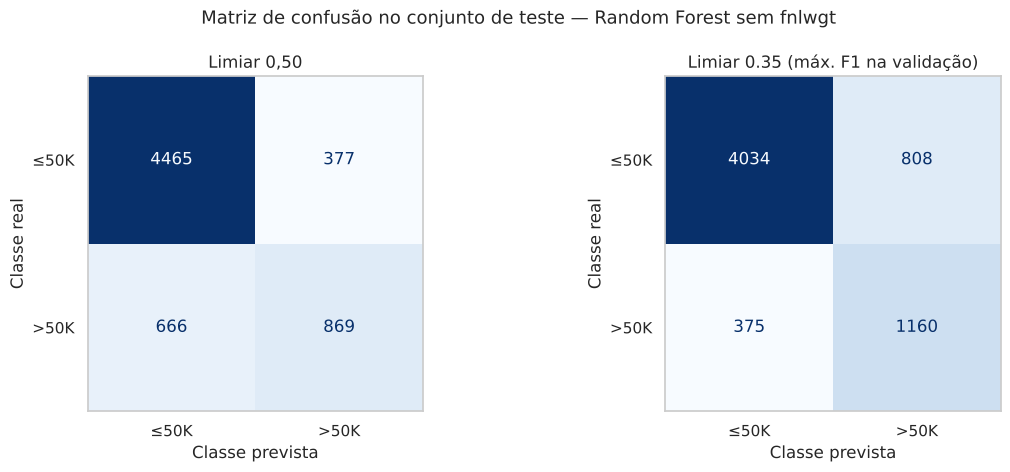

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, limiar, titulo in zip(axes, [0.5, LIMIAR],
                              ["Limiar 0,50", f"Limiar {LIMIAR:.2f} (máx. F1 na validação)"]):
    matriz = confusion_matrix(y_test, (prob_teste >= limiar).astype(int))
    ConfusionMatrixDisplay(matriz, display_labels=["≤50K", ">50K"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(titulo)
    ax.set_xlabel("Classe prevista")
    ax.set_ylabel("Classe real")
    ax.grid(False)
plt.suptitle("Matriz de confusão no conjunto de teste — Random Forest sem fnlwgt", fontsize=13)
plt.tight_layout()
plt.show()

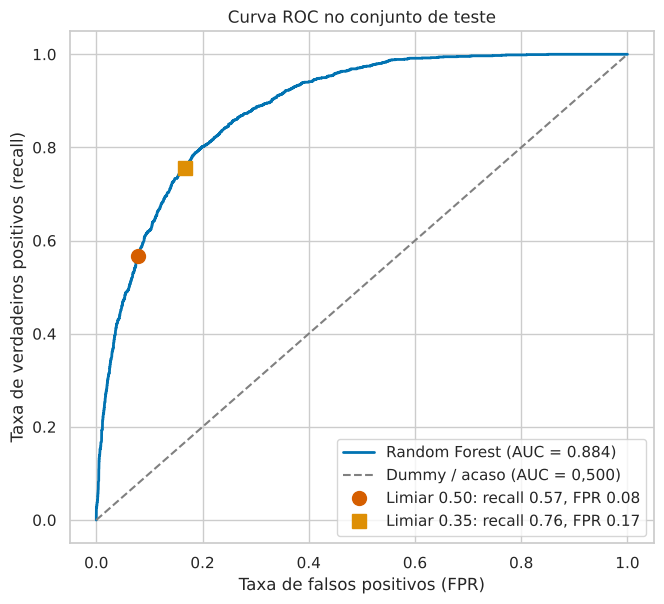

In [23]:
fpr, tpr, _ = roc_curve(y_test, prob_teste)
fig, ax = plt.subplots(figsize=(6.8, 6.2))
ax.plot(fpr, tpr, color="C0", linewidth=2, label=f"Random Forest (AUC = {roc_auc_score(y_test, prob_teste):.3f})")
ax.plot([0, 1], [0, 1], "--", color="gray", label="Dummy / acaso (AUC = 0,500)")

for limiar, marcador, cor in [(0.5, "o", "C3"), (LIMIAR, "s", "C1")]:
    previsto = prob_teste >= limiar
    taxa_fp = (previsto & (y_test == 0)).sum() / (y_test == 0).sum()
    taxa_vp = (previsto & (y_test == 1)).sum() / (y_test == 1).sum()
    ax.plot(taxa_fp, taxa_vp, marcador, color=cor, markersize=10,
            label=f"Limiar {limiar:.2f}: recall {taxa_vp:.2f}, FPR {taxa_fp:.2f}")

ax.set_title("Curva ROC no conjunto de teste")
ax.set_xlabel("Taxa de falsos positivos (FPR)")
ax.set_ylabel("Taxa de verdadeiros positivos (recall)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Análise.**

- **O teste confirma a validação:** AUC de **0,884** no teste contra 0,890 na validação cruzada. A
  diferença está dentro da variação entre folds (± 0,005) e é esperada, porque a nota do vencedor de
  uma busca é ligeiramente otimista (ele foi escolhido entre muitos candidatos).
- **Ganho sobre o baseline:** o dummy erra todas as 1.535 pessoas de renda alta. Com limiar 0,50, o
  modelo comete 1.043 erros no total (**32% menos**); com limiar 0,35, identifica **76%** das pessoas
  de renda alta. A acurácia subestima esse ganho porque seu piso, dado pelo desbalanceamento, já é 75,9%.
- **Falsos positivos e falsos negativos:** um falso positivo é uma pessoa com renda ≤50K classificada
  como >50K; um falso negativo é uma pessoa de renda alta não reconhecida. Baixar o limiar de 0,50 para
  0,35 **recupera 291 pessoas de renda alta** (falsos negativos caem de 666 para 375) ao custo de
  **431 falsos positivos a mais** (de 377 para 808).
- **Os dois limiares estão na mesma curva ROC:** mudar o corte não muda o modelo, apenas desloca o
  ponto de operação. A escolha depende do custo de cada erro na aplicação: uma campanha de prospecção
  pode preferir recall alto; uma decisão cara por pessoa pode preferir precisão alta. Adotamos o limiar
  de máximo F1 (0,35) como ponto de operação padrão.
- A acurácia cai de 83,6% para 81,5% com o limiar 0,35 mesmo com o modelo encontrando mais pessoas de
  renda alta, mais uma evidência de que a acurácia isolada é inadequada para este problema.

<a id="secao-3"></a>
# Seção 3 — Interpretação e explicabilidade

## 3.1 Modelo linear: os 3 coeficientes de maior magnitude

Na regressão logística, cada coeficiente é a variação no log da chance de renda alta associada à
coluna. Para leitura, convertemos em **razão de chances** (e^coef): valores acima de 1 multiplicam a
chance, abaixo de 1 a dividem. Os coeficientes das numéricas são comparáveis com os das categorias
porque as numéricas foram padronizadas na APS1. Comparamos as duas versões obtidas na Seção 1.3.

In [24]:
def coeficientes(modelo):
    coef = pd.Series(modelo.named_steps["modelo"].coef_[0], index=nomes_colunas(modelo))
    return coef.reindex(coef.abs().sort_values(ascending=False).index)


modelo_l2 = busca_linear.best_estimator_
modelo_l1 = clone(pipeline_linear).set_params(
    modelo__penalty="l1", modelo__l1_ratio=1, modelo__C=0.1).fit(X_train, y_train)

coef_l2, coef_l1 = coeficientes(modelo_l2), coeficientes(modelo_l1)
comparacao_coef = pd.DataFrame({
    "L2 (C=1): coluna": coef_l2.index[:6], "L2: coef": coef_l2.values[:6],
    "L1 (C=0,1): coluna": coef_l1.index[:6], "L1: coef": coef_l1.values[:6],
    "L1: razão de chances": np.exp(coef_l1.values[:6]),
}, index=range(1, 7))
display(comparacao_coef.round(3))

# Quantas pessoas sustentam cada categoria suspeita
for coluna, valor in [("native_country", "Columbia"), ("workclass", None)]:
    if valor is None:
        mascara = X_train[coluna].isna()
        valor = "Missing"
    else:
        mascara = X_train[coluna] == valor
    print(f"{coluna} = {valor}: {mascara.sum()} pessoas no treino, {y_train[mascara].mean():.1%} com renda >50K")
print("Pessoas sem workclass que também não têm occupation:",
      int((X_train["workclass"].isna() & X_train["occupation"].isna()).sum()), "de", int(X_train["workclass"].isna().sum()))

,L2 (C=1): coluna,L2: coef,"L1 (C=0,1): coluna",L1: coef,L1: razão de chances
1,workclass_Missing,-1.805,workclass_Missing,-1.709,0.181
2,native_country_Columbia,-1.466,marital_status_Married-civ-spouse,1.535,4.643
3,marital_status_Married-civ-spouse,1.363,relationship_Own-child,-1.121,0.326
4,occupation_Priv-house-serv,-1.277,relationship_Wife,1.088,2.968
5,marital_status_Married-AF-spouse,1.243,occupation_Missing,1.056,2.875
6,sex_Female,-1.242,occupation_Other-service,-0.875,0.417


native_country = Columbia: 45 pessoas no treino, 2.2% com renda >50K
workclass = Missing: 1395 pessoas no treino, 10.3% com renda >50K
Pessoas sem workclass que também não têm occupation: 1395 de 1395


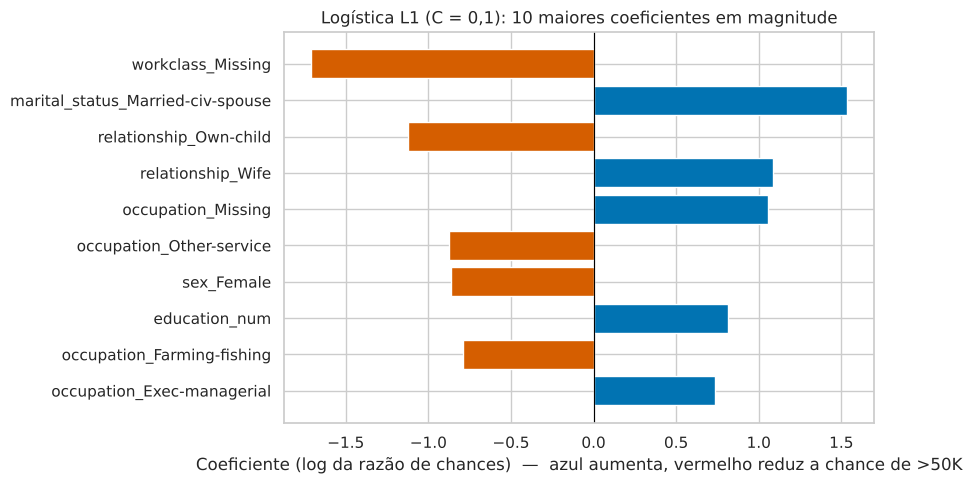

In [25]:
top_l1 = coef_l1[coef_l1 != 0].head(10)[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top_l1.index, top_l1.values, color=["C0" if v > 0 else "C3" for v in top_l1.values])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Logística L1 (C = 0,1): 10 maiores coeficientes em magnitude")
ax.set_xlabel("Coeficiente (log da razão de chances)  —  azul aumenta, vermelho reduz a chance de >50K")
plt.tight_layout()
plt.show()

**Uma armadilha das categorias raras.** No modelo L2, `native_country_Columbia` aparece como o
**2º coeficiente mais forte de todo o modelo**, sustentado por apenas 45 pessoas no treino (das quais
uma tem renda alta). É um peso inflado por amostra pequena. O modelo **L1 zera essa coluna** e tem
desempenho equivalente, por isso é ele que interpretamos.

**Os 3 maiores coeficientes da L1:**

| Coluna | Coeficiente | Razão de chances | Leitura |
|---|---|---|---|
| `workclass = Missing` | −1,71 | × 0,18 | chance de renda alta ≈ 5,5 vezes menor |
| `marital_status = Married-civ-spouse` | +1,54 | × 4,6 | chance ≈ 4,6 vezes maior |
| `relationship = Own-child` | −1,12 | × 0,33 | chance ≈ 3 vezes menor |

- **`workclass` ausente:** as 1.395 pessoas sem tipo de vínculo também não têm ocupação informada, o que
  sugere pessoas fora do mercado de trabalho (aposentados, desempregados). Isso valida a decisão da APS1
  de manter `Missing` como categoria: a ausência carrega informação. O modelo também atribui +1,06 a
  `occupation = Missing`; como as duas colunas andam juntas, devem ser lidas em conjunto
  (−1,71 + 1,06 = −0,65 para quem não tem nenhuma das duas). Colunas correlacionadas dividem o peso.
- **Casado(a) com cônjuge civil:** o fator positivo mais forte, coerente com a EDA (44,8% de renda alta
  nesse grupo contra 24% na base). Reflete associações com idade, estabilidade e composição do
  domicílio; **não é causal**.
- **`Own-child`:** pessoas que vivem como filhos do responsável pelo domicílio, tipicamente jovens que
  moram com os pais, grupo com renda alta rara.

## 3.2 Modelo ensemble: as 3 features de maior importância

Para o modelo final, comparamos a importância por impureza (MDI) com a importância por permutação,
ambas agregadas por variável original.

,MDI (treino),rank MDI,Permutação: queda de AUC,desvio,rank permutação
marital_status,0.2304,2,0.0545,0.0055,1
education_num,0.2414,1,0.0529,0.0022,2
age,0.1197,4,0.0322,0.0011,3
occupation,0.1193,5,0.0272,0.0023,4
relationship,0.1970,3,0.0168,0.0026,5
workclass,0.0465,6,0.0066,0.0008,6
sex,0.0278,7,0.0041,0.0015,7
native_country,0.0084,9,0.0008,0.0002,8
race,0.0094,8,0.0006,0.0002,9


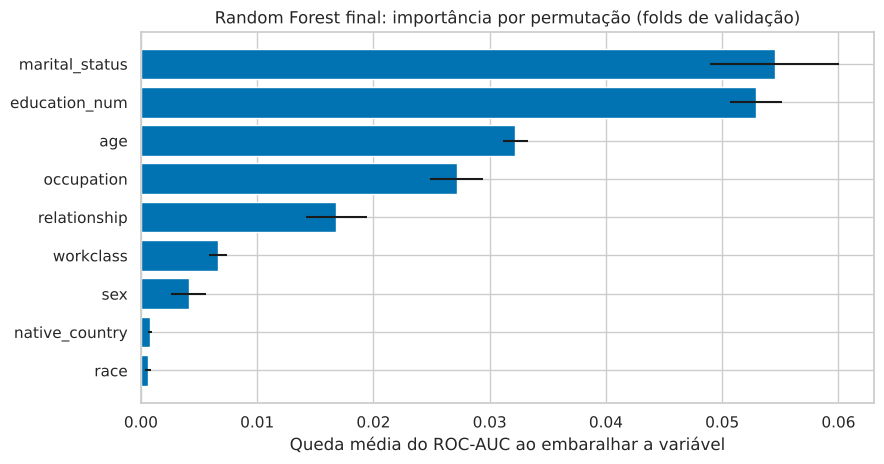

In [26]:
colunas_finais = ["age", "education_num"] + categoricas_modelo

mdi_final = pd.Series(melhor_modelo.named_steps["modelo"].feature_importances_, index=nomes_colunas(melhor_modelo))
mdi_final_var = mdi_final.groupby(mdi_final.index.map(variavel_de_origem)).sum()
perm_final = importancia_permutacao_cv(melhor_modelo, colunas_finais)

importancias_final = pd.DataFrame({
    "MDI (treino)": mdi_final_var,
    "rank MDI": mdi_final_var.rank(ascending=False).astype(int),
    "Permutação: queda de AUC": perm_final["queda_AUC"],
    "desvio": perm_final["desvio"],
    "rank permutação": perm_final["queda_AUC"].rank(ascending=False).astype(int),
}).sort_values("Permutação: queda de AUC", ascending=False)
display(importancias_final.round(4))

fig, ax = plt.subplots(figsize=(9, 4.8))
ordem = importancias_final.index[::-1]
ax.barh(ordem, importancias_final.loc[ordem, "Permutação: queda de AUC"],
        xerr=importancias_final.loc[ordem, "desvio"], color="C0")
ax.set_title("Random Forest final: importância por permutação (folds de validação)")
ax.set_xlabel("Queda média do ROC-AUC ao embaralhar a variável")
plt.tight_layout()
plt.show()

**Top 3 pela permutação: `marital_status`, `education_num` e `age`.**

- **Estado civil e escolaridade lideram nos dois métodos**: resultado robusto e coerente com a EDA (a
  taxa de renda alta vai de 16% em `HS-grad` a 77% em `Doctorate`).
- **A idade sobe na permutação** e é a 3ª variável mais útil em dados novos. A floresta consegue usar a
  relação não linear observada na EDA (sobe até 50–59 anos e cai depois), o que a logística não captura.
- **`relationship` cai do 3º lugar (MDI) para o 5º (permutação)** porque é fortemente correlacionada com
  `marital_status` (`Husband`/`Wife` praticamente implicam `Married-civ-spouse`). Ao embaralhar uma, o
  modelo ainda tem a outra, e as duas dividem o crédito. Esse é um limite conhecido da permutação com
  variáveis correlacionadas.
- Logística e floresta convergem no essencial: **estado civil e situação no domicílio** estão entre os
  fatores centrais nos dois modelos.

## 3.3 SHAP: importância global

O SHAP (Lundberg & Lee, 2017) decompõe cada previsão em contribuições aditivas: a probabilidade de uma
pessoa é igual ao **valor base** (a probabilidade média, ≈ 24%) mais a soma das contribuições de cada
feature. Usamos o `TreeExplainer` em 500 pessoas sorteadas do teste. Para facilitar a leitura, as
contribuições das colunas one-hot são **somadas por variável original**, o que é válido pela
aditividade do SHAP.

In [27]:
preprocessamento_final = melhor_modelo.named_steps["preprocessamento"]
floresta_final = melhor_modelo.named_steps["modelo"]
colunas_transformadas = nomes_colunas(melhor_modelo)
grupo_coluna = np.array([variavel_de_origem(c) for c in colunas_transformadas])

# Três casos individuais do teste (critério definido antes de olhar as explicações):
prob_teste_s = pd.Series(prob_teste, index=X_test.index)
acertos_alta = y_test[(y_test == 1) & (prob_teste_s >= LIMIAR)].index
acertos_baixa = y_test[(y_test == 0) & (prob_teste_s < LIMIAR)].index
falsos_negativos = y_test[(y_test == 1) & (prob_teste_s < LIMIAR)].index
casos = {
    "Verdadeiro positivo": (prob_teste_s[acertos_alta] - 0.85).abs().idxmin(),  # acerto confiante de renda alta
    "Verdadeiro negativo": (prob_teste_s[acertos_baixa] - 0.05).abs().idxmin(),  # acerto confiante de renda baixa
    "Falso negativo": prob_teste_s[falsos_negativos].idxmin(),                   # erro mais confiante do modelo
}

amostra = X_test.sample(500, random_state=SEMENTE)
indices = list(amostra.index) + [i for i in casos.values() if i not in amostra.index]
X_shap = preprocessamento_final.transform(X_test.loc[indices])
X_shap = X_shap.toarray() if hasattr(X_shap, "toarray") else X_shap

explicador = shap.TreeExplainer(floresta_final)
explicacao = explicador(X_shap, check_additivity=False)

# Contribuições para a classe positiva (>50K)
valores = explicacao.values[..., 1] if explicacao.values.ndim == 3 else explicacao.values
base = np.ravel(explicacao.base_values)[1] if np.ndim(explicacao.base_values) > 1 else float(np.ravel(explicacao.base_values)[0])
print(f"Valor base (probabilidade média): {base:.4f}")

# Agregação por variável original
shap_agregado = pd.DataFrame(valores, columns=colunas_transformadas, index=indices)
shap_agregado = shap_agregado.T.groupby(grupo_coluna).sum().T[colunas_finais]
dados_originais = X_test.loc[indices, colunas_finais].astype(object)
dados_originais = dados_originais.where(dados_originais.notna(), "Missing")

# Verificação da aditividade: base + soma das contribuições = probabilidade prevista
soma = base + shap_agregado.sum(axis=1)
print(f"Maior diferença entre base + SHAP e a probabilidade prevista: {np.abs(soma.values - prob_teste_s[indices].values).max():.2e}")

Valor base (probabilidade média): 0.2408
Maior diferença entre base + SHAP e a probabilidade prevista: 6.66e-15


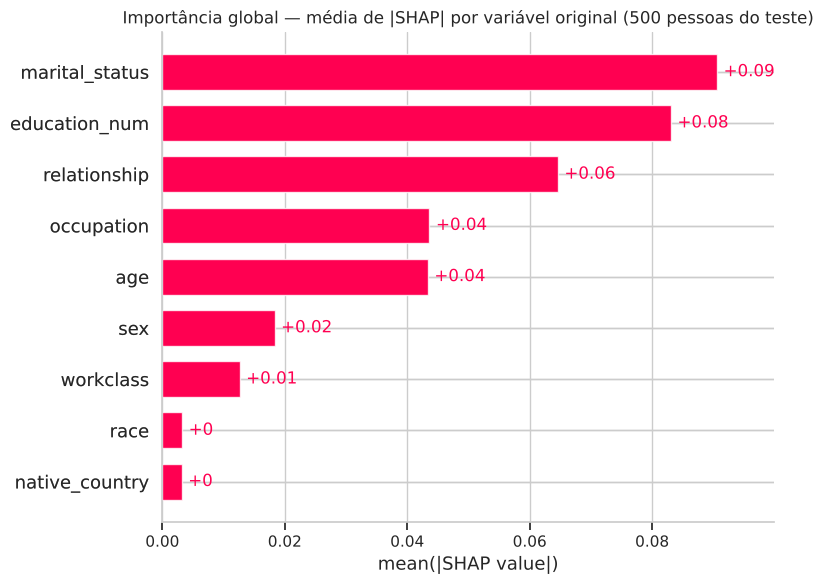

marital_status    9.06 p.p.
education_num     8.31 p.p.
relationship      6.46 p.p.
occupation        4.36 p.p.
age               4.34 p.p.
sex               1.83 p.p.
workclass         1.26 p.p.
race              0.32 p.p.
native_country    0.32 p.p.


In [28]:
explicacao_global = shap.Explanation(
    values=shap_agregado.loc[amostra.index].values,
    base_values=np.full(len(amostra), base),
    data=dados_originais.loc[amostra.index].values,
    feature_names=colunas_finais,
)
shap.plots.bar(explicacao_global, max_display=9, show=False)
plt.title("Importância global — média de |SHAP| por variável original (500 pessoas do teste)")
plt.tight_layout()
plt.show()

importancia_shap = shap_agregado.loc[amostra.index].abs().mean().sort_values(ascending=False)
print((importancia_shap * 100).round(2).astype(str).add(" p.p.").to_string())

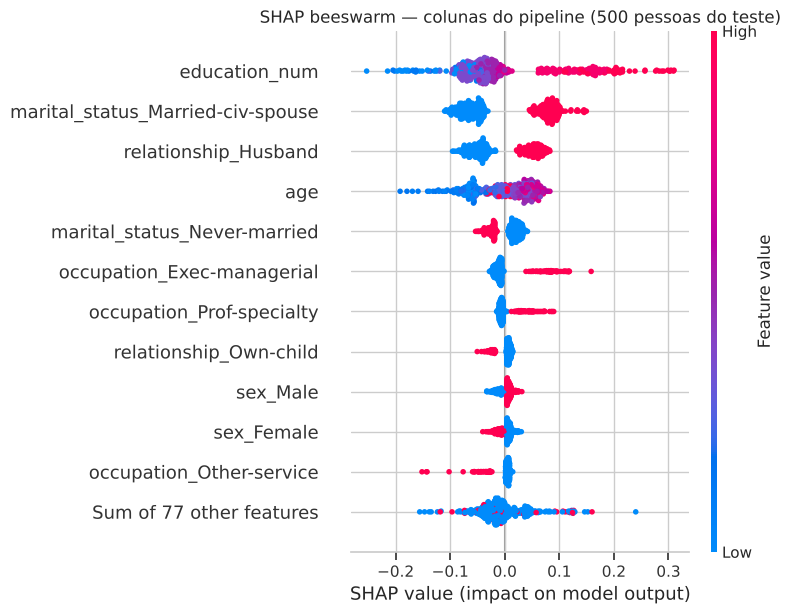

In [29]:
# Beeswarm no nível das colunas do pipeline: mostra a direção de cada efeito
n_amostra = len(amostra)
explicacao_colunas = shap.Explanation(
    values=valores[:n_amostra], base_values=np.full(n_amostra, base),
    data=X_shap[:n_amostra], feature_names=colunas_transformadas,
)
shap.plots.beeswarm(explicacao_colunas, max_display=12, show=False)
plt.title("SHAP beeswarm — colunas do pipeline (500 pessoas do teste)")
plt.tight_layout()
plt.show()

**Análise global.**

- O ranking do SHAP coincide com o da permutação: **`marital_status` (≈ ±9 p.p. em média),
  `education_num` (≈ ±8 p.p.), `relationship`, `occupation` e `age`**. `race` e `native_country` quase
  não alteram as previsões. Três métodos diferentes (MDI, permutação e SHAP) concordam sobre as
  variáveis centrais, o que aumenta a confiança na interpretação.
- **Direção dos efeitos (beeswarm):** escolaridade alta (vermelho) empurra fortemente para renda alta,
  chegando a +30 p.p. para os níveis mais altos; ser casado ou marido aumenta a probabilidade, enquanto
  `Never-married`, `Own-child` e `Other-service` a reduzem.
- **Idade não linear:** em `age`, as cores se misturam no lado positivo. As idades intermediárias
  (roxo) empurram tanto quanto ou mais que as mais altas, refletindo a curva que sobe até 50–59 anos e
  cai depois, identificada na APS1.
- `sex_Female` empurra a previsão para baixo: o modelo reproduz a diferença de renda por sexo presente
  nos dados de 1994 (discutido na Seção 4).

## 3.4 SHAP: explicação de 3 predições individuais

Os casos foram escolhidos por critério definido antes de olhar as explicações: um **acerto confiante de
renda alta** (probabilidade mais próxima de 0,85), um **acerto confiante de renda baixa** (mais próxima
de 0,05) e o **erro mais confiante** do modelo (o falso negativo com menor probabilidade).


Verdadeiro positivo — P(>50K) = 0.850 | classe real: >50K


,valor,contribuição SHAP (p.p.)
education_num,13,14.51
marital_status,Married-civ-spouse,13.49
relationship,Husband,9.22
occupation,Exec-managerial,8.82
workclass,Self-emp-inc,6.75
age,44,5.17
sex,Male,2.35
race,White,0.36
native_country,United-States,0.25


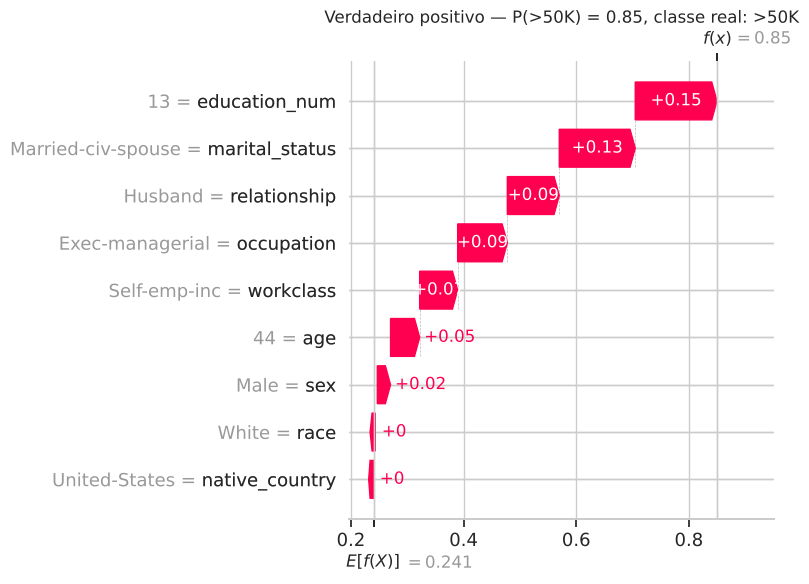


Verdadeiro negativo — P(>50K) = 0.050 | classe real: ≤50K


,valor,contribuição SHAP (p.p.)
education_num,3,-10.72
relationship,Other-relative,-5.39
marital_status,Separated,-4.00
age,42,2.17
sex,Male,2.02
occupation,Adm-clerical,-1.99
native_country,El-Salvador,-1.02
workclass,Private,-0.30
race,White,0.16


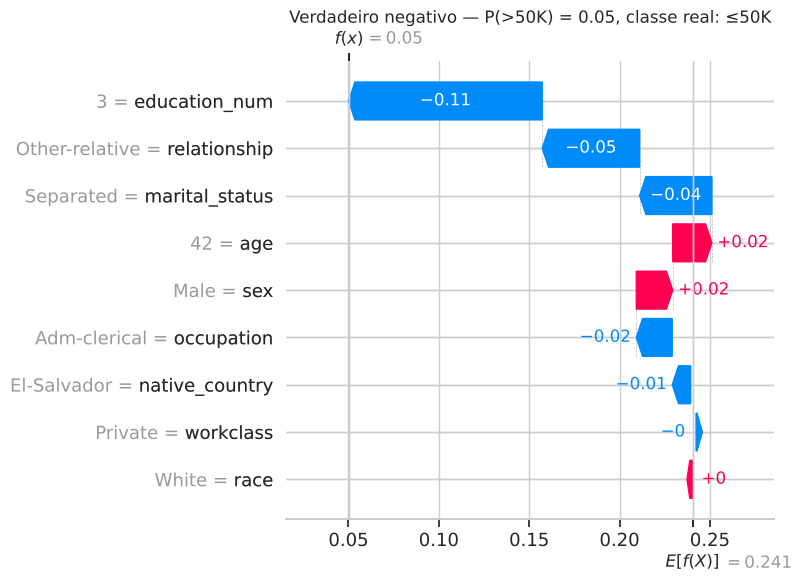


Falso negativo — P(>50K) = 0.003 | classe real: >50K


,valor,contribuição SHAP (p.p.)
marital_status,Never-married,-10.43
relationship,Own-child,-9.45
age,26,-6.44
education_num,13,6.35
occupation,Adm-clerical,-2.32
sex,Female,-1.72
race,White,0.13
native_country,United-States,0.08
workclass,Private,0.03


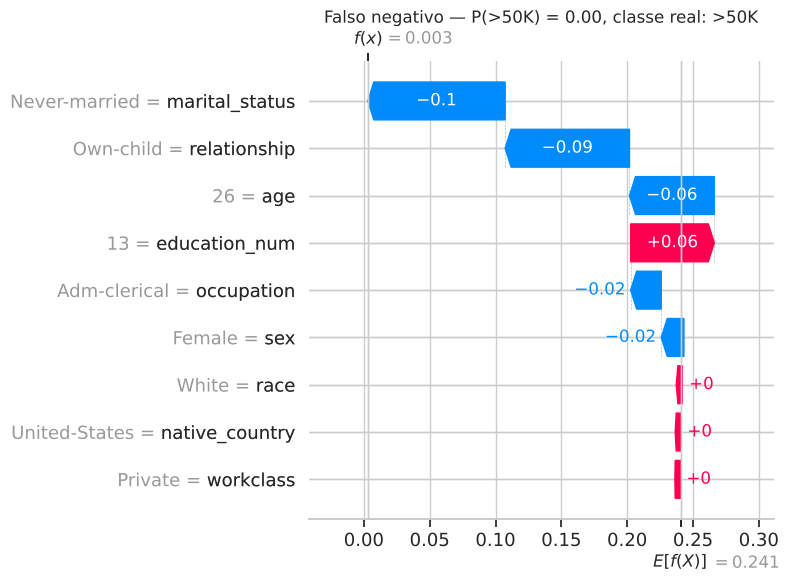

In [30]:
for nome, indice in casos.items():
    real = ">50K" if y_test[indice] == 1 else "≤50K"
    tabela = pd.DataFrame({
        "valor": dados_originais.loc[indice],
        "contribuição SHAP (p.p.)": shap_agregado.loc[indice] * 100,
    }).sort_values("contribuição SHAP (p.p.)", key=np.abs, ascending=False)
    print(f"\n{nome} — P(>50K) = {prob_teste_s[indice]:.3f} | classe real: {real}")
    display(tabela.round(2))

    explicacao_individual = shap.Explanation(
        values=shap_agregado.loc[indice].values, base_values=base,
        data=dados_originais.loc[indice].values, feature_names=colunas_finais,
    )
    shap.plots.waterfall(explicacao_individual, max_display=10, show=False)
    plt.title(f"{nome} — P(>50K) = {prob_teste_s[indice]:.2f}, classe real: {real}")
    plt.tight_layout()
    plt.show()

**Análise dos casos.**

**Verdadeiro positivo (P = 0,85, real >50K).** Homem de 44 anos, `Bachelors` (13), casado,
`Exec-managerial`, `Self-emp-inc`. Todas as contribuições relevantes apontam para renda alta:
escolaridade (+14,5 p.p.), estado civil (+13,5), `Husband` (+9,2), ocupação gerencial (+8,8) e
autônomo com empresa própria (+6,7). É o perfil típico de renda alta na base.

**Verdadeiro negativo (P = 0,05, real ≤50K).** Homem de 42 anos com escolaridade 3 (5ª–6ª série),
separado, vivendo como `Other-relative`. A escolaridade muito baixa domina (−10,7 p.p.), seguida da
situação no domicílio (−5,4) e do estado civil (−4,0). A idade empurra para cima (+2,2), já que
42 anos é uma faixa favorável, mas não compensa.

**Falso negativo (P = 0,003, real >50K): o erro mais confiante.** Mulher de 26 anos, `Bachelors`,
nunca casada, morando com os pais (`Own-child`), em ocupação administrativa. Estado civil (−10,4 p.p.),
situação no domicílio (−9,4) e idade (−6,4) puxam a probabilidade para quase zero; a graduação
(+6,4) não compensa. Na base, pessoas jovens, solteiras e que vivem com os pais raramente têm renda
alta, e o modelo aplica esse **perfil médio do grupo** a quem foge dele. O caso mostra que o modelo
usa estado civil e situação familiar como atalhos para idade, gênero e momento de vida, um ponto
aprofundado na Seção 4.

<a id="secao-4"></a>
# Seção 4 — Discussão crítica

Antes da discussão, duas verificações no conjunto de teste fundamentam as limitações do modelo:
a **calibração** das probabilidades e o **desempenho por grupo**.

Brier score — modelo: 0.1137 | dummy: 0.1828


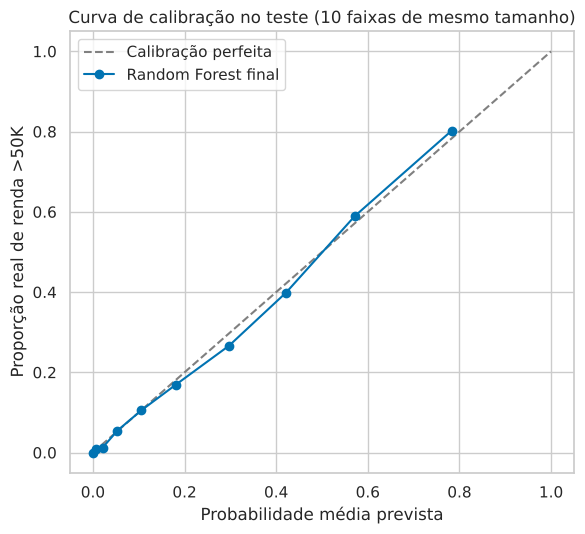

In [31]:
# Calibração: as probabilidades previstas correspondem às frequências reais?
frequencia_real, prob_media = calibration_curve(y_test, prob_teste, n_bins=10, strategy="quantile")
print(f"Brier score — modelo: {brier_score_loss(y_test, prob_teste):.4f} | dummy: "
      f"{brier_score_loss(y_test, np.full_like(prob_teste, y_train.mean())):.4f}")

fig, ax = plt.subplots(figsize=(6, 5.5))
ax.plot([0, 1], [0, 1], "--", color="gray", label="Calibração perfeita")
ax.plot(prob_media, frequencia_real, "o-", label="Random Forest final")
ax.set_title("Curva de calibração no teste (10 faixas de mesmo tamanho)")
ax.set_xlabel("Probabilidade média prevista")
ax.set_ylabel("Proporção real de renda >50K")
ax.legend()
plt.tight_layout()
plt.show()

In [32]:
# Desempenho por grupo no limiar de operação
previsto_teste = (prob_teste >= LIMIAR).astype(int)


def metricas_por_grupo(coluna):
    linhas = []
    for grupo, indices_grupo in X_test.groupby(coluna).groups.items():
        pos = X_test.index.get_indexer(indices_grupo)
        real, prev, prob = y_test.to_numpy()[pos], previsto_teste[pos], prob_teste[pos]
        linhas.append({
            coluna: grupo, "n": len(pos),
            "taxa real >50K": real.mean(),
            "taxa prevista >50K": prev.mean(),
            "recall (renda alta reconhecida)": prev[real == 1].mean(),
            "taxa de falsos positivos": prev[real == 0].mean(),
            "precisão": real[prev == 1].mean(),
            "ROC-AUC": roc_auc_score(real, prob),
        })
    return pd.DataFrame(linhas).set_index(coluna)


display(metricas_por_grupo("sex").round(3))
display(metricas_por_grupo("race").round(3))

,n,taxa real >50K,taxa prevista >50K,recall (renda alta reconhecida),taxa de falsos positivos,precisão,ROC-AUC
sex,,,,,,,
Female,2098,0.114,0.115,0.603,0.053,0.595,0.917
Male,4279,0.303,0.403,0.784,0.238,0.589,0.856


,n,taxa real >50K,taxa prevista >50K,recall (renda alta reconhecida),taxa de falsos positivos,precisão,ROC-AUC
race,,,,,,,
Amer-Indian-Eskimo,67,0.060,0.104,0.500,0.079,0.286,0.889
Asian-Pac-Islander,214,0.252,0.290,0.704,0.150,0.613,0.873
Black,561,0.127,0.152,0.746,0.065,0.624,0.931
Other,45,0.111,0.133,0.600,0.075,0.500,0.860
White,5490,0.255,0.329,0.759,0.182,0.588,0.878


A calibração está **adequada**: em cada faixa, a probabilidade média prevista fica próxima da proporção
real (por exemplo, ≈ 0,78 previsto contra 0,80 observado na faixa mais alta), e o Brier score é 0,114
contra 0,183 do dummy. A descalibração, comum em florestas (Niculescu-Mizil & Caruana, 2005), **não** é
um problema relevante aqui. O desempenho por grupo, porém, revela uma limitação séria.

## 4.1 Limitações do modelo

**1. Taxas de erro desiguais entre homens e mulheres.** No limiar de operação, o modelo reconhece
**60%** das mulheres de renda alta contra **78%** dos homens, e a taxa de falsos positivos é de 5% para
mulheres contra 24% para homens. A precisão é semelhante (≈ 59%), mas a chance de uma pessoa de renda
alta ser identificada depende do sexo, o que viola o critério de *igualdade de oportunidade* de Hardt,
Price e Srebro (2016). Numa aplicação real, como oferta de crédito ou de produtos financeiros, mulheres
qualificadas seriam sistematicamente sub-atendidas. Uma mitigação possível são limiares por grupo ou
restrições de equidade no treino, com custo em outras métricas que precisa ser explicitado.

**2. Dependência de atributos substitutos (*proxies*), que impede uma correção simples.** Remover a
coluna `sex` não eliminaria o viés: `relationship` contém `Husband` e `Wife`, que codificam o sexo quase
perfeitamente, e as variáveis mais importantes do modelo (estado civil e situação no domicílio) são
atalhos para idade, gênero e momento de vida. Barocas, Hardt e Narayanan (2023) mostram que a "justiça
por desconhecimento" falha justamente quando há atributos correlacionados ao atributo sensível. Além
disso, o modelo aplica o perfil médio do grupo a indivíduos atípicos e produz erros extremamente
confiantes, como o falso negativo da Seção 3.4 (P = 0,003 para uma pessoa de renda alta).

## 4.2 Limitações dos dados

**1. Defasagem temporal e limiar nominal.** Os dados são do censo de 1994, e o limiar de US$ 50 mil é
nominal: corrigido pela inflação, corresponde a mais que o dobro em dólares atuais. A composição do
mercado de trabalho mudou desde então (participação feminina, ocupações em tecnologia, escolaridade
média), então as relações aprendidas não descrevem a população atual. Ding et al. (2021) documentam
essas limitações do Adult e propõem conjuntos derivados de pesquisas censitárias recentes
(*folktables*) como substitutos. Sem dados atuais, o modelo só pode ser usado como estudo, nunca como
ferramenta de decisão.

**2. Variáveis ausentes nesta versão e dados autodeclarados.** A versão do Kaggle utilizada não contém
`hours-per-week`, `capital-gain` e `capital-loss`, presentes no Adult original da UCI (Becker & Kohavi,
1996) e diretamente ligadas à renda. A curva de aprendizado (Seção 1.7) é coerente com essa limitação: a
validação estabiliza com cerca de 17 mil exemplos, indicando que o teto está na informação disponível,
não no volume de dados. Além disso, as respostas do censo são autodeclaradas, sujeitas a erros e
arredondamentos, e o alvo binário descarta a informação de quão acima ou abaixo de US$ 50 mil cada
pessoa está.

## 4.3 Operacionalização e manutenção

**1. Monitoramento contínuo com retreino orientado por gatilhos.** Em produção, monitorar (a) a
distribuição das entradas (por exemplo, idade, escolaridade e a frequência de categorias novas ou
`Missing`), para detectar *data drift*; e (b) quando houver rótulos, o ROC-AUC, o recall e a taxa de
falsos positivos **globais e por sexo e raça**, para detectar *concept drift* e piora de equidade. Quedas
acima de limites definidos disparam retreino e nova validação (Gama et al., 2014). Sem esse ciclo, o
modelo se degrada silenciosamente, um dos principais componentes da dívida técnica de sistemas de ML
descritos por Sculley et al. (2015).

**2. Versionamento do pipeline completo e documentação com *model card*.** O artefato implantado deve
ser o `Pipeline` inteiro (pré-processamento, modelo e limiar 0,35), serializado com as versões do
scikit-learn e dos dados de treino, garantindo que treino e produção transformem as entradas de forma
idêntica (por exemplo, a categoria `Missing` e o `handle_unknown="ignore"` do one-hot). O modelo deve ser
acompanhado de um *model card* (Mitchell et al., 2019) com uso pretendido, usos proibidos (decisão
automatizada sobre indivíduos sem revisão humana), métricas globais e por grupo, e as limitações
desta seção.

<a id="conclusao"></a>
# Conclusão

Partindo do pipeline da APS1, comparamos três modelos com a mesma métrica (ROC-AUC) e os mesmos folds.
A regressão logística regularizada mostrou-se limitada por viés (0,884), enquanto a Random Forest, ao
capturar relações não lineares como a da idade, foi superior em todos os folds (0,890). A remoção de
`fnlwgt`, motivada pela EDA e confirmada pelo contraste entre MDI e permutação, manteve o desempenho e
reduziu o sobreajuste, originando o modelo final.

No teste, usado uma única vez, o modelo atingiu AUC de 0,884 e, com limiar escolhido na validação,
reconheceu 76% das pessoas de renda alta. As explicações (coeficientes, permutação e SHAP) convergem
para estado civil, escolaridade e idade como fatores centrais. A análise crítica, porém, mostra que o
modelo erra de forma desigual entre homens e mulheres e se apoia em atributos substitutos, e que os
dados são antigos e incompletos. O resultado é adequado como estudo de modelagem, mas qualquer uso
real exigiria dados atuais, auditoria de equidade e monitoramento contínuo.

<a id="referencias"></a>
# Referências

1. BAROCAS, S.; HARDT, M.; NARAYANAN, A. *Fairness and Machine Learning: Limitations and Opportunities*. Cambridge: MIT Press, 2023. Disponível em: https://fairmlbook.org
2. BECKER, B.; KOHAVI, R. *Adult* [dataset]. UCI Machine Learning Repository, 1996. https://doi.org/10.24432/C5XW20
3. BREIMAN, L. Random Forests. *Machine Learning*, v. 45, p. 5–32, 2001. https://doi.org/10.1023/A:1010933404324
4. DING, F.; HARDT, M.; MILLER, J.; SCHMIDT, L. Retiring Adult: New Datasets for Fair Machine Learning. *Advances in Neural Information Processing Systems (NeurIPS)*, v. 34, 2021.
5. GAMA, J. et al. A Survey on Concept Drift Adaptation. *ACM Computing Surveys*, v. 46, n. 4, 2014. https://doi.org/10.1145/2523813
6. HARDT, M.; PRICE, E.; SREBRO, N. Equality of Opportunity in Supervised Learning. *Advances in Neural Information Processing Systems (NeurIPS)*, v. 29, 2016.
7. LUNDBERG, S. M.; LEE, S.-I. A Unified Approach to Interpreting Model Predictions. *Advances in Neural Information Processing Systems (NeurIPS)*, v. 30, 2017.
8. MITCHELL, M. et al. Model Cards for Model Reporting. *Proceedings of the Conference on Fairness, Accountability, and Transparency (FAT\*)*, p. 220–229, 2019. https://doi.org/10.1145/3287560.3287596
9. NICULESCU-MIZIL, A.; CARUANA, R. Predicting Good Probabilities with Supervised Learning. *Proceedings of the 22nd International Conference on Machine Learning (ICML)*, p. 625–632, 2005.
10. PEDREGOSA, F. et al. Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, v. 12, p. 2825–2830, 2011.
11. SANDMANN, H. *Machine Learning* — material da disciplina, Insper, 2026.2. https://insper.github.io/ML/pt/2026.2/
12. SCULLEY, D. et al. Hidden Technical Debt in Machine Learning Systems. *Advances in Neural Information Processing Systems (NeurIPS)*, v. 28, 2015.
13. STROBL, C.; BOULESTEIX, A.-L.; ZEILEIS, A.; HOTHORN, T. Bias in Random Forest Variable Importance Measures: Illustrations, Sources and a Solution. *BMC Bioinformatics*, v. 8, 25, 2007. https://doi.org/10.1186/1471-2105-8-25